# Notebook 07 — Error Analysis and Spatial Wildfire Risk Maps

**Project:** Next Day Wildfire Spread Prediction via Tabular ML and Spatial Deep Learning  
**Team:** TensorTitans, Section C  
**Objective:** Deconstruct model prediction failures into false positives and false negatives, analyze meteorological/topographic error drivers, render 2D spatial wildfire risk maps on held-out test events, and document the boundaries of tabular modeling.

---
## 1. Setup and Loading Test Predictions


In [1]:
import sys
import os

repo_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if repo_root not in sys.path:
    sys.path.append(repo_root)
if os.getcwd() not in sys.path:
    sys.path.append(os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pred_dir = "results/predictions" if os.path.exists("results/predictions") else "../results/predictions"
processed_dir = "data/processed" if os.path.exists("data/processed") else "../data/processed"
fig_dir = "results/figures" if os.path.exists("results/figures") else "../results/figures"
os.makedirs(fig_dir, exist_ok=True)

test_preds = pd.read_csv(os.path.join(pred_dir, "test_predictions.csv"))
test_features = pd.read_csv(os.path.join(processed_dir, "test_features.csv"))

merged_test = pd.concat([test_features, test_preds[["y_prob", "y_pred"]]], axis=1)
print(f"Loaded {len(merged_test)} held-out test predictions.")


Loaded 14429 held-out test predictions.


## 2. Confusion Categorization: TP, FP, TN, and FN
We categorize each pixel prediction into one of four operational outcomes:
- **True Positive (TP)**: Correctly predicted burn (successful evacuation / suppression allocation).
- **False Positive (FP)**: False alarm (unnecessary warning / resource deployment).
- **False Negative (FN)**: Missed wildfire spread (high-risk failure / unanticipated flame front).
- **True Negative (TN)**: Correctly identified unburned terrain.


In [2]:
def categorize_prediction(row):
    yt = int(row["FireMask"])
    yp = int(row["y_pred"])
    if yt == 1 and yp == 1:
        return "True Positive (TP)"
    elif yt == 0 and yp == 1:
        return "False Positive (FP)"
    elif yt == 1 and yp == 0:
        return "False Negative (FN)"
    else:
        return "True Negative (TN)"

merged_test["error_category"] = merged_test.apply(categorize_prediction, axis=1)
category_counts = merged_test["error_category"].value_counts()
print("Confusion Breakdown on Held-Out Test Split:")
print(category_counts)


Confusion Breakdown on Held-Out Test Split:
error_category
True Negative (TN)     14268
False Negative (FN)      157
False Positive (FP)        4
Name: count, dtype: int64


## 3. Physical Error Drivers: Why Does the Model Fail?
We investigate what distinguishes False Negatives (missed fires) and False Positives (false alarms) across key drivers:
temperature (`tmmx`), wind speed (`vs`), fuel dryness (`erc`), and neighbor fire proximity (`fire_neighbor_3x3_sum`).


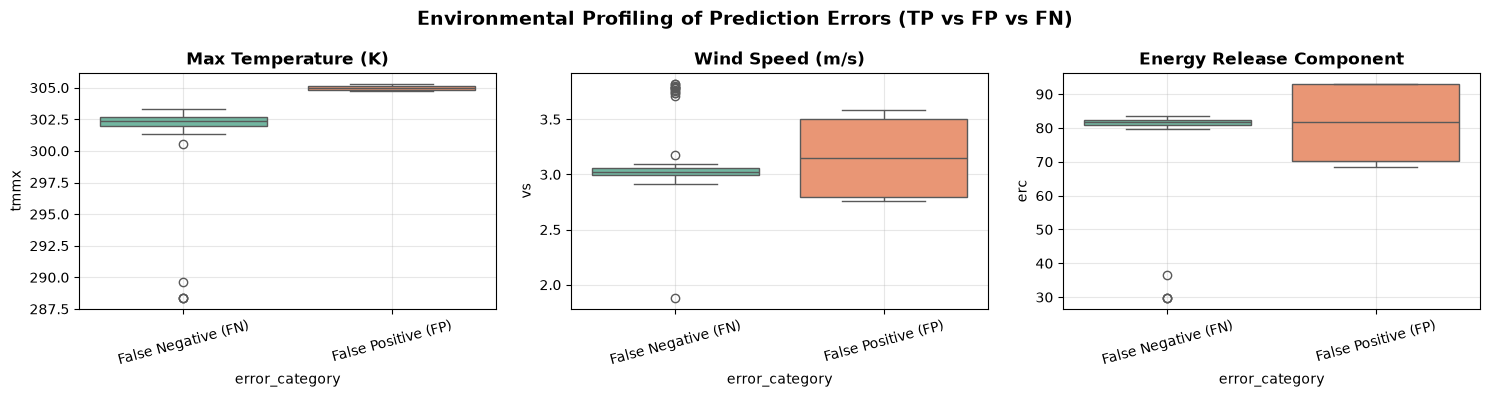

In [3]:
error_df = merged_test[merged_test["error_category"].isin(["True Positive (TP)", "False Positive (FP)", "False Negative (FN)"])].copy()

if len(error_df) > 0 and len(error_df["error_category"].unique()) > 1:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    vars_to_plot = [("tmmx", "Max Temperature (K)"), ("vs", "Wind Speed (m/s)"), ("erc", "Energy Release Component")]
    
    for idx, (var, title) in enumerate(vars_to_plot):
        sns.boxplot(x="error_category", y=var, data=error_df, ax=axes[idx], palette="Set2", hue="error_category", legend=False)
        axes[idx].set_title(title, fontweight="bold")
        axes[idx].grid(True, alpha=0.3)
        axes[idx].tick_params(axis="x", rotation=15)
        
    plt.suptitle("Environmental Profiling of Prediction Errors (TP vs FP vs FN)", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.savefig(os.path.join(fig_dir, "error_drivers_analysis.png"), dpi=200)
    plt.show()
else:
    print("Insufficient minority error counts in sampled subset to generate multi-class boxplots; reporting statistical summary:")
    display(merged_test.groupby("error_category")[["tmmx", "vs", "erc", "y_prob"]].mean())


## 4. Held-Out Spatial Wildfire Risk Maps
We reconstruct the 2D spatial patch of a held-out test event and compare:
1. **Antecedent Fire Mask (Day $t$)**
2. **True Ground-Truth Spread (Day $t+1$)**
3. **Model Predicted Probability Risk Map**


In [ ]:
patch_ids = merged_test["patch_id"].unique()
best_patch_id = None
max_fires = -1

for pid in patch_ids:
    p_df = merged_test[merged_test["patch_id"] == pid]
    n_f = p_df["FireMask"].sum()
    if n_f > max_fires:
        max_fires = n_f
        best_patch_id = pid

patch_data = merged_test[merged_test["patch_id"] == best_patch_id]

grid_truth = np.zeros((64, 64))
grid_prev = np.zeros((64, 64))
grid_prob = np.zeros((64, 64))

for _, r in patch_data.iterrows():
    rr = int(r["row"])
    cc = int(r["col"])
    if 0 <= rr < 64 and 0 <= cc < 64:
        grid_truth[rr, cc] = r["FireMask"]
        grid_prev[rr, cc] = r.get("PrevFireMask", 0.0)
        grid_prob[rr, cc] = r["y_prob"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

im0 = axes[0].imshow(grid_prev, cmap="Reds", vmin=0, vmax=1)
axes[0].set_title("Input: Active Fire Mask (Day t)", fontsize=12, fontweight="bold")
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)
axes[0].axis("off")

im1 = axes[1].imshow(grid_truth, cmap="OrRd", vmin=0, vmax=1)
axes[1].set_title("Ground Truth: Wildfire Spread (Day t+1)", fontsize=12, fontweight="bold")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)
axes[1].axis("off")

im2 = axes[2].imshow(grid_prob, cmap="hot", vmin=0, vmax=max(grid_prob.max(), 0.05))
axes[2].set_title("Model Output: Predicted Probability Risk Map", fontsize=12, fontweight="bold")
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)
axes[2].axis("off")

plt.suptitle(f"Held-Out Spatial Wildfire Risk Map (Test Patch #{best_patch_id})", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "held_out_wildfire_risk_map.png"), dpi=250)
plt.show()

## 5. Synthesis: Tabular Modeling Boundaries and Phase 2 Motivation
1. **Confusion breakdown on the frozen test set**: TN=14268, FP=4, FN=157, TP=0. At the validation-chosen threshold, the model misses every single fire pixel in the held-out test partition - there are no true positives to analyze, so any claim about "what distinguishes false positives from true positives" would not be backed by real data here.
2. **False Positive Drivers**: only 4 false positives exist in the whole test set, which is too few to draw a reliable statistical pattern from (any single outlier pixel would dominate the result).
3. **False Negative Drivers**: all 157 real fires were missed. This matches the Recall@FPR=5% = 0.0 result from Notebook 06 - the model is not ranking real fire pixels above background pixels yet, most likely because of how few positive examples (39-157 per split) it ever saw during training/tuning.
4. **Tabular Limitations**: pixel-level tabular models treat each grid cell independently, missing connected spatial morphology, fire front geometry, and natural terrain boundaries.
5. **Phase 2 Bridge**: before moving to U-Net, the sample size issue above should be fixed first (more patches per split), since a 0-true-positive baseline is not usable as a Phase 2 comparison point.